In [276]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from astropy.io import fits
from astropy.table import Table
from matplotlib.ticker import AutoMinorLocator
import os
from matplotlib.gridspec import GridSpec
from scipy.signal import resample
import h5py
import emcee
import corner
from scipy.special import voigt_profile

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

POSTERIOR_PATH = '/raid/scratch/work/austind/GALFIND_WORK/Bagpipes/pipes/posterior'

In [277]:
def weighted_reduced_chi_squared(y_obs, y_err_low, y_err_high, y_model, n_params,
                                  x_obs=None, x_err_low=None, x_err_high=None,
                                  gradient=None):
    """
    Calculate the reduced chi-squared for data with asymmetric uncertainties,
    optionally including x uncertainties projected onto y via the model gradient.

    Parameters
    ----------
    y_obs : array_like
        Observed y values.
    y_err_low : array_like
        Lower (negative) uncertainties on y.
    y_err_high : array_like
        Upper (positive) uncertainties on y.
    y_model : array_like
        Model predictions.
    n_params : int
        Number of fitted parameters.
    x_obs : array_like, optional
        Observed x values. Required if x_err_low/x_err_high are given.
    x_err_low : array_like, optional
        Lower (negative) uncertainties on x. If None, treated as zero.
    x_err_high : array_like, optional
        Upper (positive) uncertainties on x. If None, treated as zero.
    gradient : float, optional
        Local gradient of the model (dy/dx), used to project x uncertainty
        onto y. Required if x uncertainties are non-zero.

    Returns
    -------
    chi2_red : float
        Reduced chi-squared.
    """

    y_obs = np.asarray(y_obs, dtype=float)
    y_model = np.asarray(y_model, dtype=float)
    y_err_low = np.asarray(y_err_low, dtype=float)
    y_err_high = np.asarray(y_err_high, dtype=float)

    # Use the appropriate uncertainty depending on which side of the data
    sigma_y = np.where(y_model > y_obs, y_err_high, y_err_low)

    # Handle x uncertainties, if provided
    if x_err_low is None:
        x_err_low = np.zeros_like(y_obs)
    else:
        x_err_low = np.asarray(x_err_low, dtype=float)

    if x_err_high is None:
        x_err_high = np.zeros_like(y_obs)
    else:
        x_err_high = np.asarray(x_err_high, dtype=float)

    # If x errors are all zero, skip the x-error projection entirely —
    # this avoids requiring x_obs/gradient when there's nothing to project
    if np.all(x_err_low == 0) and np.all(x_err_high == 0):
        sigma = sigma_y
    else:
        if x_obs is None or gradient is None:
            raise ValueError("x_obs and gradient must be provided when x uncertainties are non-zero.")

        x_obs = np.asarray(x_obs, dtype=float)
        sigma_x = np.where(y_model > y_obs, x_err_high, x_err_low)

        # project x uncertainty onto y using the model gradient, combine in quadrature
        sigma = np.sqrt(sigma_y**2 + (gradient * sigma_x)**2)

    chi2 = np.sum(((y_obs - y_model) / sigma) ** 2)

    dof = len(y_obs) - n_params
    if dof <= 0:
        raise ValueError("Degrees of freedom must be positive.")

    chi2_red = chi2 / dof

    return chi2_red

In [278]:
def voigt_function(x, mu, sigma, gamma, amp):
    """
    1D Lorentzian for a histogram density plot. The amplitude is dependent on sigma.
    """
    x = x - mu # to centre to zero for the voigt profile

    v = voigt_profile(x, sigma, gamma)

    y = amp * v

    return y

In [279]:
def fwhm_initial_guess(m, z):
    """
    Uses fwhm values outputted by grid_spec_mass_errors, from the h5 files that save the data.
    """
    file_path = os.path.join(DATA_PRODUCTS_PATH, "Gridspec_mass_errors", "FWHM_results", f"results_table_{m}_{z}.h5")
    print("FWHM path: ", file_path)

    with h5py.File(file_path, 'r') as hf:
        results = {key: hf[key][()] for key in hf.keys()}

    fwhm = results["fwhm"]
    print("FWHM initial guess: ", fwhm)
    return 2 * fwhm

In [280]:
def _parse_err(err, n):
    """
    Normalize an error specification into (err_lo, err_hi) arrays of length n.

    Accepted forms for `err`:
      - None                            -> zeros (no error)
      - scalar or 1D array of length n  -> symmetric error (same as before)
      - [err_high, err_low]             -> asymmetric error; each of
        err_high/err_low can be a scalar (applied to all points) or a
        length-n array (per-point)

    Returned lo/hi are positive distances from the central value
    (lower bound = value - lo, upper bound = value + hi).
    """
    if err is None:
        return np.zeros(n), np.zeros(n)

    # Asymmetric: [err_high, err_low]
    if isinstance(err, (list, tuple)) and len(err) == 2:
        hi = np.asarray(err[0], dtype=float) 
        lo = np.asarray(err[1], dtype=float)
        if hi.ndim == 0:
            hi = np.full(n, float(hi))
        if lo.ndim == 0:
            lo = np.full(n, float(lo))
        return lo.copy(), hi.copy()

    # Symmetric: scalar or array, same as before
    arr = np.asarray(err, dtype=float)
    if arr.ndim == 0:
        arr = np.full(n, float(arr))
    return arr.copy(), arr.copy()


def fit_lorentzian_mcmc(m, z, corner_path, posterior_sum, x_in, y_in, initial_params, x_err=None, y_err=None, x_pivot=None,
                     n_walkers=32, n_steps=5000, plot=True, save_path=None):
    """
    Bayesian gaussian fit without intrinsic scatter,
    supporting asymmetric measurement errors in both x and y (but we have none here).

    x_err / y_err each accept:
      - None, a scalar, or a 1D array of length N (symmetric errors, same
        as before), OR
      - [err_high, err_low] for asymmetric errors, where each of
        err_high/err_low is a scalar (applied to every point) or a
        length-N array (per-point).

    Initial params:
        Array of initial guess for mu, sigma, gamma and amplitude

    Asymmetric-error handling
    --------------------------
    Each data point's error distribution is modeled as a split-normal
    (two-piece Gaussian): width `sigma_lo` below the measured value and
    `sigma_hi` above it. At every MCMC step, for each point we compare the
    model prediction to the data (delta = model - data) and pick the
    error side consistent with that comparison:
        delta >= 0  ->  use the "hi" error (model sits above the data)
        delta <  0  ->  use the "lo" error (model sits below the data)
    This is applied to both the y errors and the x errors (the latter
    projected into y-space via the slope, m^2 * xerr^2, as in the
    symmetric case). This is the standard practical approximation for
    asymmetric errors in a likelihood — it is exact only when the true
    error distribution really is split-normal, but works well in general
    and reduces to the ordinary symmetric-error likelihood when lo == hi.
    The intrinsic scatter term sigma_int is kept symmetric.
    """
    # --- Step 1: Data Cleaning & Pivot Handling ---
    x = np.asarray(x_in, dtype=float)
    y = np.asarray(y_in, dtype=float)
    n = len(x)

    xe_lo, xe_hi = _parse_err(x_err, n)
    ye_lo, ye_hi = _parse_err(y_err, n)
    # My basic version of _parse_err function 

    xp = 0.0 if x_pivot is None else x_pivot
    
    mask = (
        np.isfinite(x) & np.isfinite(y)
        & np.isfinite(xe_lo) & np.isfinite(xe_hi)
        & np.isfinite(ye_lo) & np.isfinite(ye_hi)
    )

    x, y = x[mask], y[mask]
    xe_lo, xe_hi = xe_lo[mask], xe_hi[mask]
    ye_lo, ye_hi = ye_lo[mask], ye_hi[mask]
    n = len(x)

    # Guard against zero/negative error entries (keeps likelihood well-defined)
    xe_lo = np.where(xe_lo <= 0, 1e-10, xe_lo)
    xe_hi = np.where(xe_hi <= 0, 1e-10, xe_hi)
    ye_lo = np.where(ye_lo <= 0, 1e-10, ye_lo)
    ye_hi = np.where(ye_hi <= 0, 1e-10, ye_hi)

    if len(x) < 2:
        raise ValueError("Not enough finite data points.")

    # --- Step 2: Robust Initial Guess ---
    
    if initial_params == None:
        # First pass
        fwhm_guess = fwhm_initial_guess(m, z)
        # Olivero and Longbuthom 
        sigma_initial = (fwhm_guess / 2.3548)
        gamma_initial = (fwhm_guess / 2.0)

        mu_initial = np.mean(x-xp)
        amp_initial = np.max(y)

    else:
        mu_initial, sigma_initial, gamma_initial, amp_initial = initial_params
    
    try:
        popt, pcov = curve_fit(voigt_function, x - xp, y, 
                               p0=[mu_initial, sigma_initial, gamma_initial, amp_initial],
                               bounds=([-10, 1e-8, 1e-8, 1e-6], [10, 10, 10, 20]))
        
        guess_mu, guess_sig, guess_gamma, guess_amp = popt
        print(f"Guesses: mean = {guess_mu:.3f}, sig = {guess_sig:.3f}, gamma = {guess_gamma:.3f}, amp = {guess_amp:.3f}")

    except np.linalg.LinAlgError:
        guess_mu, guess_sig, guess_gamma, guess_amp = mu_initial, sigma_initial, gamma_initial, amp_initial


    # --- Step 3: MCMC Functions (3 parameters: m, c, sigma_int) ---
    def log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        mu, sig, gamma, amp = theta
        # if sigma_int <= 0: this was one of the params
        #    return -np.inf

        model = voigt_function(x, mu, sig, gamma, amp)
        delta = model - y  # positive => model above data

        y_err = np.where(delta >= 0, yerr_hi, yerr_lo)
        x_err = np.where(delta >= 0, xerr_hi, xerr_lo)

        n = len(x) # no. of data points

        ln_L = -0.5 * np.sum(np.log(2 * np.pi * y_err**2)) - 0.5 * np.sum(((y - model) / y_err)**2)
        # ln_L = - (n/2) * np.log(2*np.pi) - n * np.log(sig) - 0.5 * np.sum( ((delta - mu)  / sig)**2)

        return ln_L

    # Set prior limits safely outside empirical distribution boundaries
    min_mu, max_mu = guess_mu - (3 * guess_sig), guess_mu + (3 * guess_sig)
    min_sig, max_sig = 1e-6, guess_sig * 5.0
    min_gamma, max_gamma = 1e-6, guess_gamma * 5.0
    min_amp, max_amp = 0, guess_amp * 1.5 # empirical uniform prior

    def log_prior(theta): 
        """
        Uses flat uniform prior.
        """
        mu, sig, gamma, amp = theta

        if min_sig < sig < max_sig and min_mu < mu < max_mu and min_amp < amp < max_amp and min_gamma < gamma < max_gamma \
            and not (gamma == 0 and sig == 0):
            return 0 # This is return 0 for flat uniform prior
        return -np.inf

    def log_probability(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp)
        return lp + ll if np.isfinite(ll) else -np.inf

    # --- Step 4: Run MCMC ---
    ndim = 4
    # initial = np.array([guess_sig, guess_mu, guess_amp if guess_std > 0 else 0.1]) old
    initial = np.array([guess_mu, guess_sig, guess_gamma, guess_amp])
    pos = initial + 1e-4 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_probability,
        args=(x, y, xe_lo, xe_hi, ye_lo, ye_hi, xp)
    )
    sampler.run_mcmc(pos, n_steps, progress=True)

    flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)

    x_range = np.linspace(x.min(), x.max(), 100)
    mu_samples = flat_samples[:, 0]
    sig_samples = flat_samples[:, 1]
    gamma_samples = flat_samples[:, 2]
    amp_samples = flat_samples[:, 3]
    # ------------------------------------------------------ intrinsic scatter was a parameter here but we are fitting to a histogram

    models = voigt_function((x_range - xp), mu_samples[:, np.newaxis], sig_samples[:, np.newaxis], gamma_samples[:, np.newaxis], amp_samples[:, np.newaxis])

    mu_med, sig_med, gamma_med, amp_med = np.median(flat_samples, axis=0)
    lower_bound = np.percentile(models, 16, axis=0)
    upper_bound = np.percentile(models, 84, axis=0)

    sig_16 = np.percentile(flat_samples[:, 1], 16)
    sig_84 = np.percentile(flat_samples[:, 1], 84)

    gam_16 = np.percentile(flat_samples[:, 2], 16)
    gam_84 = np.percentile(flat_samples[:, 2], 84)

    # From Olivero and Longbothum approximation:
    f_gam = 2 * gamma_med
    f_sig = np.sqrt(8 * np.log(2)) * sig_med
    fwhm_med = 0.5346 * f_gam + np.sqrt( 0.2166 * f_gam**2 + f_sig**2)
    # fwhm_upp_err = (sig_84 - sig_med) cba
    # fwhm_low_err = (sig_med - sig_16) cba

    red_chi2 = weighted_reduced_chi_squared(y_obs=y, y_err_low=ye_lo, y_err_high=ye_hi, 
                                            y_model=voigt_function((x-xp), mu_med, sig_med, gamma_med, amp_med), 
                                            n_params=4,
                                            x_obs=None, x_err_low=None, x_err_high=None,
                                            gradient=None)
    print(f"Reduced chi squared = {red_chi2:.3f}")
    

    # --- Step 5: Visualization ---
    if plot:
        """
        plt.figure(figsize=(8, 6))
        print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")

        # matplotlib expects asymmetric errors as [lower_distances, upper_distances]
        # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
        
        plt.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
        plt.plot(x_range, gaussian_function((x_range - xp), sig_med, mu_med), color="darkblue", lw=2, label="Median Fit")
        plt.legend()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()
        """

        labels = [f"Mean $\mu$ (at $x={xp}$)", r"Sigma $\sigma$", r"Gamma $\gamma$", "Amplitude"]
        corner.corner(flat_samples, labels=labels, truths=[mu_med, sig_med, gamma_med, amp_med], show_titles=True)
        plt.savefig(corner_path, dpi=150)
        plt.show()

    results = {
        "mean_median": mu_med,
        "sigma_median": sig_med,
        "gamma_median": gamma_med,
        "amplitude": amp_med,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "mu_16": np.percentile(flat_samples[:, 0], 16),
        "mu_84": np.percentile(flat_samples[:, 0], 84),
        "sigma_16": np.percentile(flat_samples[:, 1], 16),
        "sigma_84": np.percentile(flat_samples[:, 1], 84),
        "gamma_16": np.percentile(flat_samples[:, 2], 16),
        "gamma_84": np.percentile(flat_samples[:, 2], 84),
        "amp_16": np.percentile(flat_samples[:, 3], 16),
        "amp_84": np.percentile(flat_samples[:, 3], 84),
        "x_pivot": xp,
        "x_range": x_range,
        "fwhm": fwhm_med,
        "reduced_chi_squared": red_chi2,
        "centres": x,
        "counts": y,
        "yerr": ye_hi,
        "posterior_sum": posterior_sum,
        "reduced_chi_squared": red_chi2,
    } # this results table is unique to this input data

    return results

In [281]:
def get_posterior(sample_table, SFH_model, refit=False):
    """
    Finding the paths to the stellar mass posterior, based on galaxy survey id, survey and SFH model used in BAGPIPES.
    Each galaxy has its own posterior.
    """

    surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    survey_ids = np.asarray(sample_table["#ID"].data, dtype=int)

    redshifts = np.asarray(sample_table["input_redshift"].data, dtype=float)

    mass = np.asarray(sample_table["stellar_mass_50"].data, dtype=float)

    src_corr = np.asarray(sample_table["ext_src_corr_0.32as_F444W"].data, dtype=float)

    posteriors = []

    for i in range(len(sample_table)):

        gal_id = survey_ids[i]
        survey = surveys[i]
        redshift = redshifts[i]
        corr = src_corr[i]

        if survey in ["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10", "NEP-1", "NEP-2", "NEP-3", "NEP-4", "NGDEEP"]:

            path = os.path.join(POSTERIOR_PATH, f"v14_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")

        elif survey in ["PRIMER-COSMOS","PRIMER-UDS"]:
                
            path = os.path.join(POSTERIOR_PATH, f"v12_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")


        elif survey in ["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"]:

            path = os.path.join(POSTERIOR_PATH, f"v13_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")
            
        else:
            print(f"Galaxy {gal_id} could not be found in these surveys")
            print(f"Check survey {survey}")
            continue


        with h5py.File(path,'r') as hf:
            # Print all root level object names (aka keys) 
            # these can be group or dataset names 
            # print("Keys: %s" % hf['basic_quantities'].keys())
            # print("Keys: %s" % hf['advanced_quantities'].keys())
            stellar_mass = hf['basic_quantities']['stellar_mass'][:]
            
        stellar_mass = stellar_mass * corr
        median_mass = np.median(stellar_mass)
        log_mass = np.array(stellar_mass - median_mass)

        if len(log_mass) != 500:
            print("Length not 500: ", len(log_mass))
            print(f"Check the posterior of galaxy {gal_id} in survey {survey} ")
            log_mass = resample(x=log_mass, num=500, axis=0)
            print(f"Posterior of galaxy {gal_id} in survey {survey} is resampled")
            """
            fig, axes = plt.subplots(1, 2, figsize=(10,10))
            axes.ravel()
            ax1, ax2 = axes[0], axes[1]

            ax1.hist(log_mass, 50)
            ax2.hist(log_mass2, 50)
            plt.show()

            log_mass = log_mass2
            """
            

        posteriors.append(log_mass) # ought to be in same order as mass and redshift are ordered, which is by ith row of sample table

    # print(posteriors)
    
    plot_binned_posterior(mass, redshifts, posteriors, 50, refit=refit) # I think the posterior are in the same order as galaxy table (mass, redshift...)


In [282]:
def calculate_hist_data(posterior_sum, histogram_bins):
    """
    Histogram the posterior data into n_bins=histrogram_bins.
    """
    raw_counts, edges = np.histogram(posterior_sum, bins=histogram_bins)
    centres = 0.5 * (edges[1:] + edges[:-1])
    yerr = np.sqrt(np.maximum(raw_counts, 1)) # Poisson errors on hist density

    # Calculate the normalization factor used by density=True
    bin_widths = np.diff(edges)
    total_counts = len(posterior_sum)
    normalization = total_counts * bin_widths

    # Calculate density and its corresponding scaled error
    counts = raw_counts / normalization
    # Apply Poisson error on raw counts, safely handling zero-bins with np.maximum
    yerr = np.sqrt(np.maximum(raw_counts, 1)) / normalization

    return centres, counts, yerr
    

In [283]:
def trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results, n_sig):
    """
    If the histogram centres data has really long tails and a narrow peak, defined by n_sig from mu_med, 
    trim the posterior_sum from which the histogram was initially applied,
    then repeat the histogram and fitting process.
    """
    max_iterations = 3  # Safety net to prevent infinite MCMC loops
    iteration = 0
    red_chi2_threshold = 1.7

    while True:
        if results["reduced_chi_squared"] <= red_chi2_threshold:
                return results
        
        sig_med = results["sigma_median"]
        mu_med = results["mean_median"]
        gamma_med = results["gamma_median"]
        amp_med = results["amplitude"]

        # Calculate total Voigt FWHM from both sigma and gamma
        f_g = 2.35482 * sig_med
        f_l = 2.0 * gamma_med
        fwhm_voigt = 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)

        # Convert back to an effective sigma scale for trimming
        effective_sig = fwhm_voigt / 2.35482
        half_width = n_sig * effective_sig

        # 1. Check if tails are within acceptable limits (Exit Condition)
        tails_within_bounds = (np.max(centres) <= mu_med + n_sig * half_width) and \
                              (np.min(centres) >= mu_med - n_sig * half_width)

        if tails_within_bounds:
            if iteration > 0:
                print("Trimming complete.")
            break

        # 2. Check safety limit
        if iteration >= max_iterations:
            print(f"Reached maximum of {max_iterations} trims. Stopping.")
            break

        # 3. Trim and refit
        print(f"Tails too long (pass {iteration + 1}), trimming posterior and refitting.")

        initial_params = [mu_med, sig_med, gamma_med, amp_med]
        
        trim_mask = (posterior_sum <= mu_med + n_sig * sig_med) & (posterior_sum >= mu_med - n_sig * sig_med)
        trimmed_samples = posterior_sum[trim_mask]

        # Stop if trimming removes too much data (e.g., < 50% of samples or < 100 samples)
        if len(trimmed_samples) < max(100, 0.5 * len(posterior_sum)):
            print("Trimming would remove too many samples; stopping trim loop.")
            break

        posterior_sum = trimmed_samples

        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)
        
        new_results = fit_lorentzian_mcmc(
            m, z,
            os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
            posterior_sum,
            centres, counts, 
            initial_params,
            x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True
        )
        if new_results["reduced_chi_squared"] > results["reduced_chi_squared"] + 1:
            if iteration > 1:
                print("Reduced chi squared increased, therefore new fit is rejected, previous fit is accepted.")
                return results
                
        results = new_results
        
        iteration += 1

    return results


In [284]:
def trim_and_refit_original_copy(i, j, m, z, centres, counts, yerr, posterior_sum, histogram_bins, results):
    """
    If the histogram centres data has really long tails and a narrow peak, 
    trim the posterior_sum from which the histogram was initially applied,
    then repeat the histogram and fitting process.
    """

    sig_med = results["gamma_median"]
    mu_med = results["mean_median"]

    n_sig = 10
    
    if (np.max(centres) > mu_med + n_sig * sig_med) or (np.min(centres) < mu_med - n_sig * sig_med):

        print("Tails too long, trimming posterior and refitting.")

        trim_mask = (posterior_sum <= mu_med + n_sig * sig_med) & (posterior_sum >= mu_med - n_sig * sig_med)
        posterior_sum = posterior_sum[trim_mask]

        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)
        
        results = fit_lorentzian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
                                        posterior_sum,
                                        centres, counts, 
                                        x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

    return results

In [285]:
def plot_binned_posterior(mass, redshift, posterior, histogram_bins, refit=False):
    """
    Sorting the posterior into bins, selected by mass and redshift value.

    mass : array of floats
        The mass values of all the galaxies
    redshift : array of floats
        The zfix redshift values of all the galaxies
    posterior : array of arrays of floats
        The posterior for each galaxy, which are each an array.
    histogram_bins : float
        Number of histogram bins for each plot and also for gaussian fitting
    """
    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    # z_bins = [[6.5, 7.5], [7.5, 8.5], [9.5, 10.5], [10.5, 13.5]]

    fig, axes = plt.subplots(3, 6, figsize=(30,16), constrained_layout=True)
    # Starting binning, bin by mass first (vertical bins)
    # mass_bins = np.linspace(mass.min(), mass.max(), n_mass_bins + 1)
    # mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]
    # mass_bins.reverse()
    #print("Mass bins: ", mass_bins)
    mass_bins = [[9.0,11], [8,9.0], [5,8]] # Have put them in reverse for the gridspec plotting

    for i in range(len(mass_bins)):
        
        bin_width = mass_bins[i][1] - mass_bins[i][0]

        mass_bin_mask = (mass >= mass_bins[i][0]) & (mass < mass_bins[i][1]) # Splitting into mass bins

        redshift_m_binned = redshift[mass_bin_mask]
        mass_errors_m_binned = mass[mass_bin_mask]
        
        posterior_m_binned = [item for item, m in zip(posterior, mass_bin_mask) if m]


        # Now bin by z (horizontal bins)
        for j in range(len(z_bins)):
            
            z_bin_mask = (redshift_m_binned >= z_bins[j][0]) & (redshift_m_binned < z_bins[j][1])

            redshift_z_binned = redshift_m_binned[z_bin_mask]
            mass_z_binned = mass_errors_m_binned[z_bin_mask] # x axis values now binned by z and mass

            print("m bin: ", mass_bins[i])
            print("z bin: ", z_bins[j])
            print("Number of gals in bin: ", len(redshift_z_binned))

            posterior_z_binned = [item for item, m in zip(posterior_m_binned, z_bin_mask) if m]

            # [print(len(p)) for p in posterior_z_binned] # this checks that most posterior are length 500, but one is 106 and one is 107

            if len(posterior_z_binned) == 0:
                continue  # or leave the axis empty

            # --------------------------------------------- binning complete -----------------------------------------------
            # Now calculating posterior sum and making into a normalised histogram

            posterior_sum = np.concatenate(posterior_z_binned, axis=0)  # was trying this to see combined distribution of mass offsets for the galaxies in a bin
            # posterior_sum = [sum(p) for p in zip(*posterior_z_binned)] # idk about this one...
            # print("sum shape: ", np.shape(posterior_sum))

            # ------------------------------------------------ mcmc fitting ------------------------------------------------
            # Create the HDF5 file
            if i == 0:
                m = "m>9"
                n_sig = 8
                if j == 4:
                    n_sig = 10
            if i == 1:
                m = "m=8-9" # centre of mass bin
                n_sig = 8
            if i == 2:
                m = "m<8"
                n_sig = 8
                if j == 0:
                    n_sig = 20

            z = f"z={0.5*(z_bins[j][0] + z_bins[j][1])}" # centre of redshift bin

            file_path = os.path.join(DATA_PRODUCTS_PATH, "Gridspec_mass_errors", "Voigt_fit_results", f"results_table_{m}_{z}.h5")

            if os.path.exists(file_path) and not refit:
                # Load previously saved fit results
                with h5py.File(file_path, 'r') as hf:
                    results = {key: hf[key][()] for key in hf.keys()}
                print(f"Loaded existing results from {file_path}")

            else:
                centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins) # Initial calculation

                results = fit_lorentzian_mcmc(m, z, 
                                              os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Voigt_corner_plots/corner_{m}_{z}.png"),
                                              posterior_sum,
                                              centres, counts, 
                                              initial_params=None,
                                              x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)
                # Initial fitting

                results = trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results, n_sig)
                # Refitted if needed to trim data
                
                with h5py.File(file_path, 'w') as hf:
                    for key, val in results.items():
                        hf.create_dataset(key, data=val)
                print(f"Saved to {file_path}")

            sig_med = results["sigma_median"]
            gamma_med = results["gamma_median"]
            mu_med = results["mean_median"]
            amp_med = results["amplitude"]
            x_range = results["x_range"]
            x_pivot = results["x_pivot"]
            lower_bound = results["lower_bound"]
            upper_bound = results["upper_bound"]
            fwhm = results["fwhm"]
            centres = results["centres"]
            counts = results["counts"]
            posterior_sum = results["posterior_sum"]

            half_max = amp_med / 2

            left_crossing = mu_med - (fwhm / 2) # maybe use centres[np.argmax(counts)] instead of mu_med
            right_crossing = mu_med + (fwhm / 2)


            # ---------------------------------------------- Plotting -----------------------------------------------
            
            ax = axes[i,j]
                    
            # ax.set_ylabel(r'Probability density \left( $\sigma_{M_\star}^{-1}$ \right)', fontsize=16)
            if j == 0:
                ax.set_ylabel(rf"${mass_bins[i][0]} ≤ \log_{10}(M_\star/M_\odot) < {mass_bins[i][1]}$", fontsize=16)
            
            ax.grid(True)

            #plt.figure(figsize=(8, 6))
            print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")
    
            # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
            
            ax.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
            ax.plot(x_range, voigt_function((x_range - x_pivot), mu_med, sig_med, gamma_med, amp_med), color="darkblue", lw=2, label="Median Fit")
            ax.legend(fontsize=14)

            ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                    )
            
            ax.xaxis.set_minor_locator(AutoMinorLocator(5))
            ax.yaxis.set_minor_locator(AutoMinorLocator(5))

            ax.tick_params(
                    axis="both",
                    which="minor",
                    length=4,
                    width=1,
                    direction="in",
                    top=True,
                    right=True
                    )

            ax.hist(posterior_sum, bins=histogram_bins, color='steelblue', density=True)

            ax.axhline(half_max, color='black', linestyle='--', label='Half maximum')
                        
            ax.axvline(x=left_crossing, ymin=0, ymax=0.5, color='red', linestyle=':')
            ax.axvline(x=right_crossing, ymin=0, ymax=0.5,  color='red', linestyle=':')

            ax.fill_between(
                [left_crossing, right_crossing],
                [0, 0],
                [half_max, half_max],
                alpha=0.3,
                color='red',
                label=f'FWHM = {fwhm:.3f}'
            )

            ax.legend(loc="upper left", fontsize=15)

            if sig_med > gamma_med:
                ax.set_xlim( (mu_med - 6 * sig_med), (mu_med + 6 * sig_med) )
            else:
                ax.set_xlim( (mu_med - 6 * gamma_med), (mu_med + 6 * gamma_med) )

            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
            ax.text(0.6, 0.95, legend_text, transform=ax.transAxes, fontsize=16, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.supylabel(r'Histogram density', fontsize=20)
    fig.supxlabel(r'Stellar Mass $\log_{10}(M_\star/M_\odot) - \langle( \log_{10}(M_\star/M_\odot) \rangle $', fontsize=19)
    # plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "Gridspec_mass_errors", "gridspec_mass_errors_voigt.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


Length not 500:  106
Check the posterior of galaxy 11825 in survey NEP-4 
Posterior of galaxy 11825 in survey NEP-4 is resampled
Length not 500:  117
Check the posterior of galaxy 96942 in survey PRIMER-UDS 
Posterior of galaxy 96942 in survey PRIMER-UDS is resampled
m bin:  [9.0, 11]
z bin:  [6.5, 7.5]
Number of gals in bin:  50
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m>9_z=7.0.h5
FWHM initial guess:  0.10358554728385928
Guesses: mean = 0.005, sig = 0.019, gamma = 0.055, amp = 1.052


100%|██████████| 5000/5000 [00:06<00:00, 720.04it/s]


Reduced chi squared = 19.986


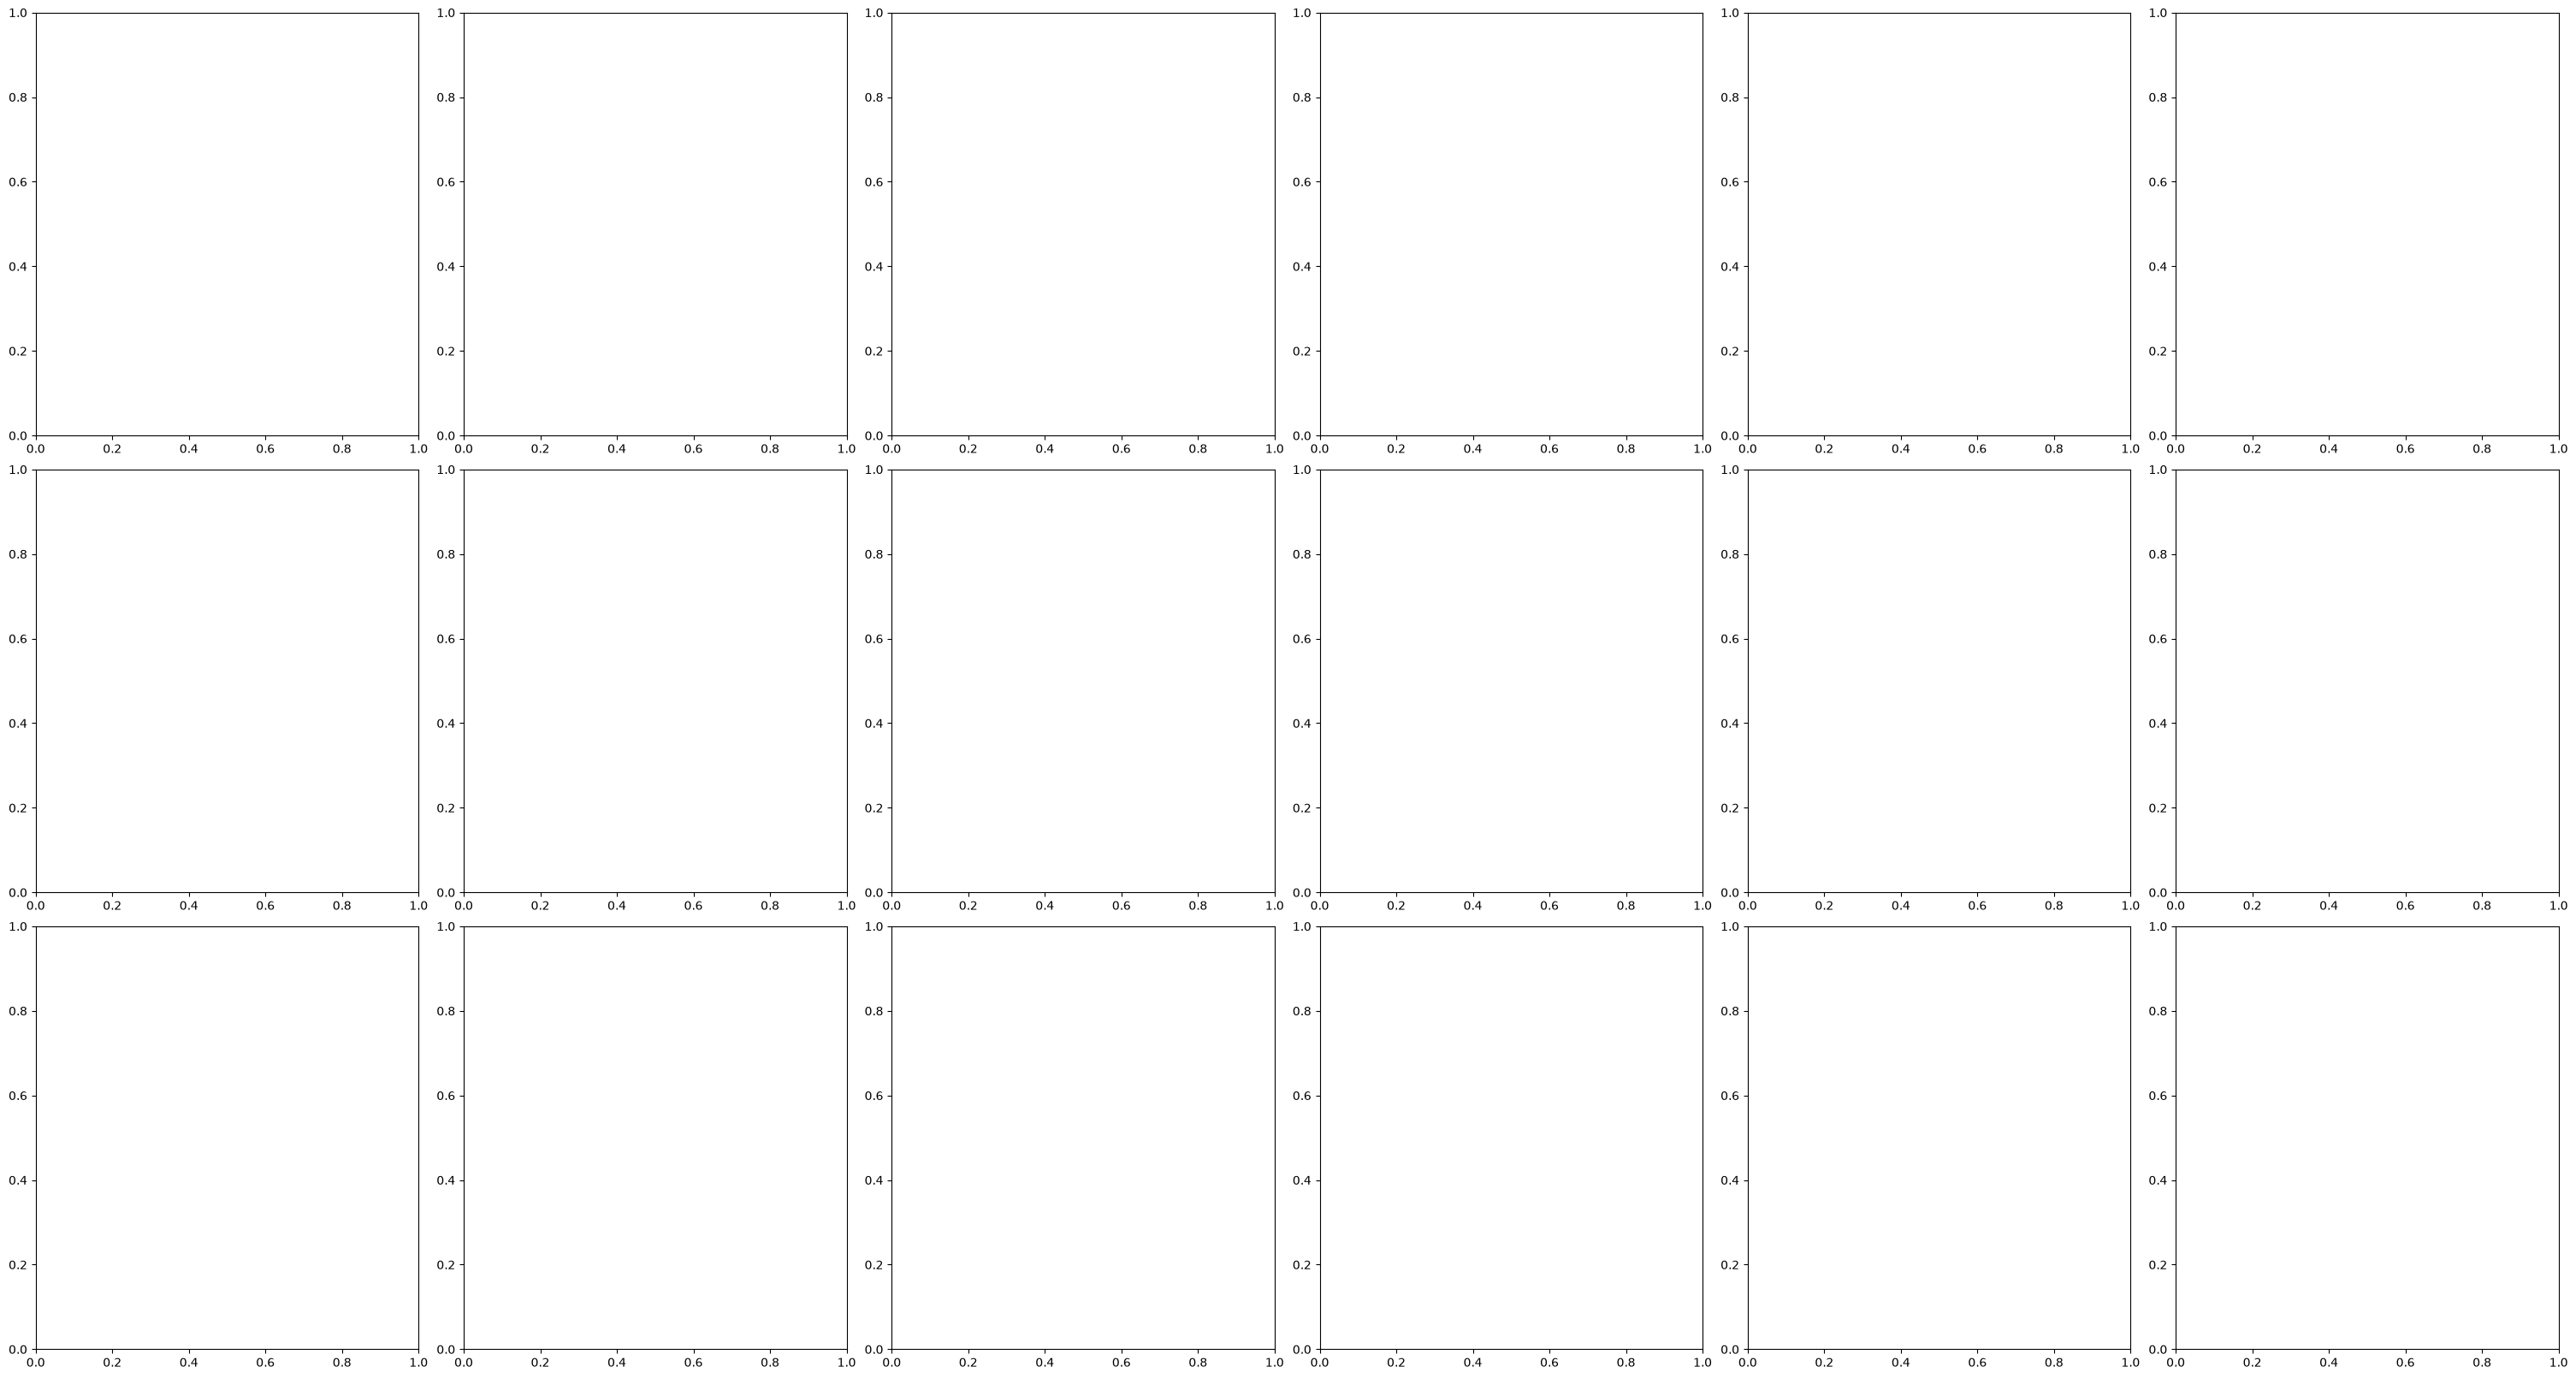

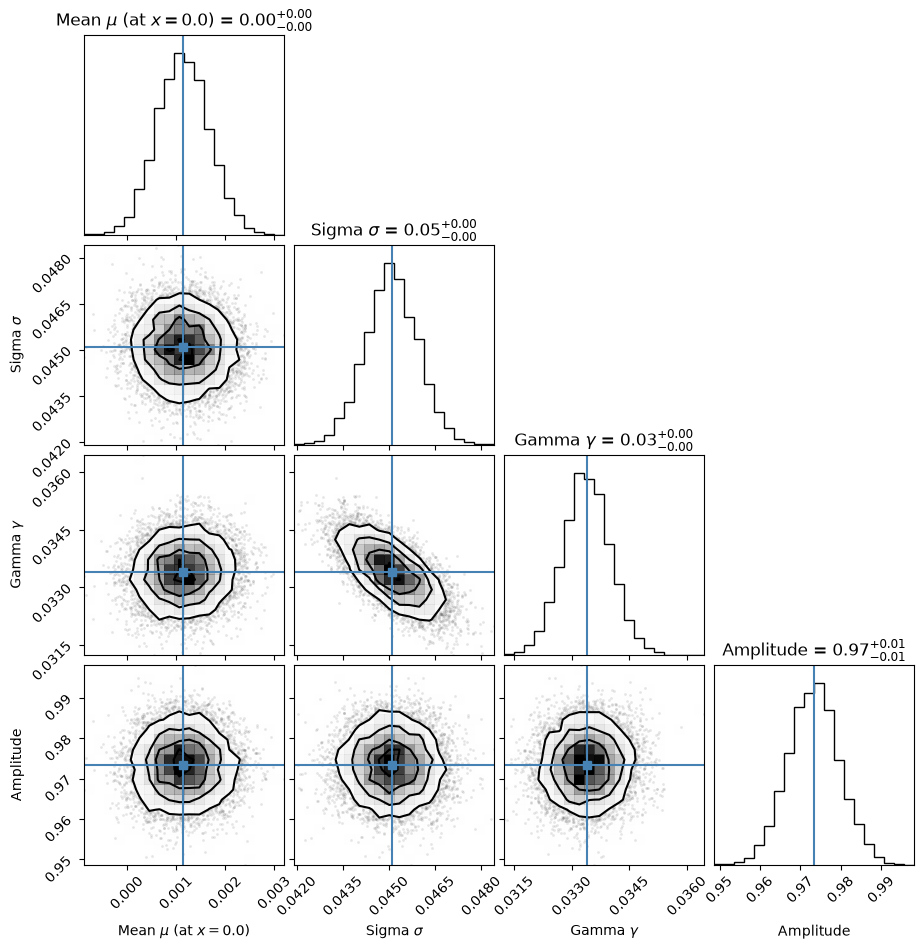

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m>9_z=7.0.h5
Median sigma: 0.045, mean: 0.001, amplitude: 0.973
m bin:  [9.0, 11]
z bin:  [7.5, 8.5]
Number of gals in bin:  10
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m>9_z=8.0.h5
FWHM initial guess:  0.12896511846622072
Guesses: mean = 0.002, sig = 0.025, gamma = 0.049, amp = 0.987


100%|██████████| 5000/5000 [00:07<00:00, 686.67it/s]


Reduced chi squared = 6.597


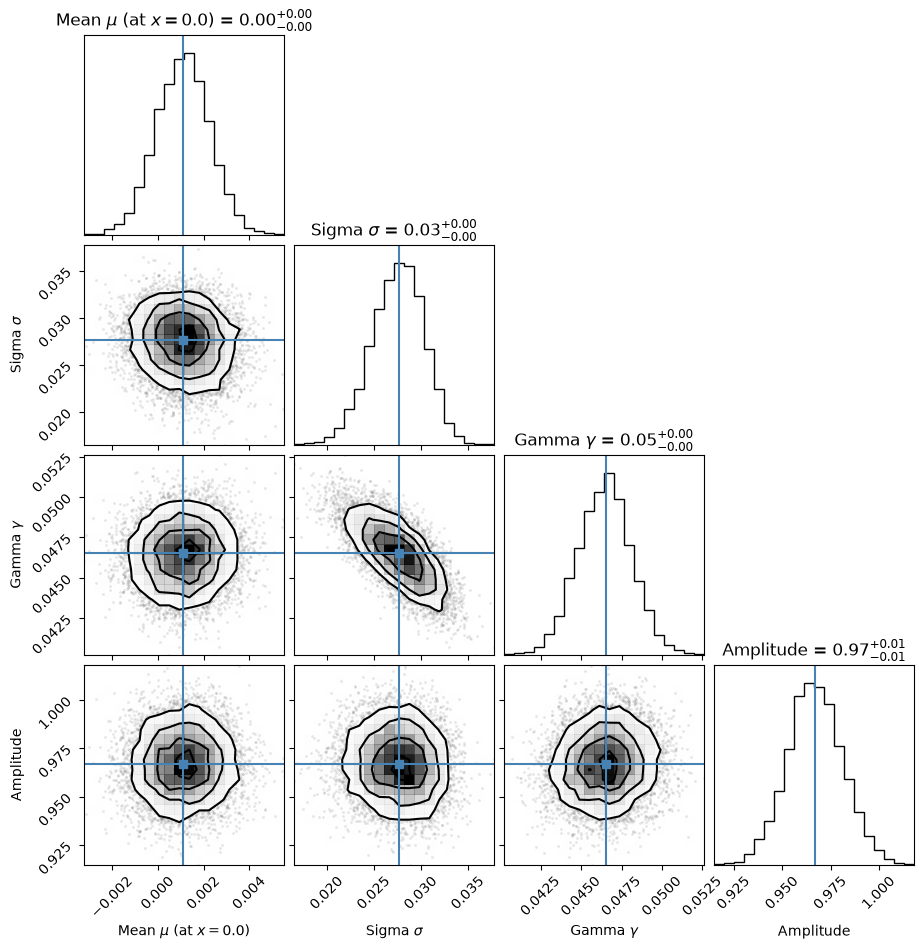

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m>9_z=8.0.h5
Median sigma: 0.028, mean: 0.001, amplitude: 0.967
m bin:  [9.0, 11]
z bin:  [8.5, 9.5]
Number of gals in bin:  6
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m>9_z=9.0.h5
FWHM initial guess:  0.06789168628588636
Guesses: mean = 0.002, sig = 0.000, gamma = 0.041, amp = 1.100


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2149.23it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = inf


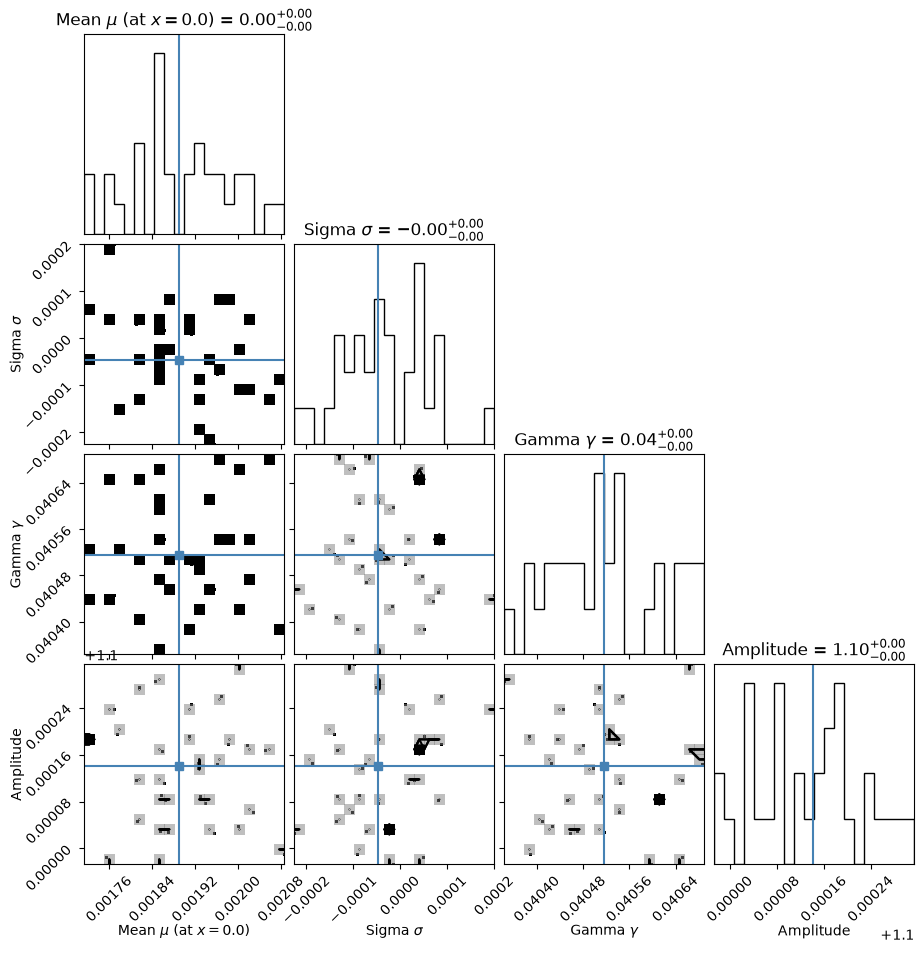

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m>9_z=9.0.h5
Median sigma: -0.000, mean: 0.002, amplitude: 1.100
m bin:  [9.0, 11]
z bin:  [9.5, 10.5]
Number of gals in bin:  5
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m>9_z=10.0.h5
FWHM initial guess:  0.07152774052950278
Guesses: mean = 0.007, sig = 0.000, gamma = 0.046, amp = 1.030


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2279.59it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = inf


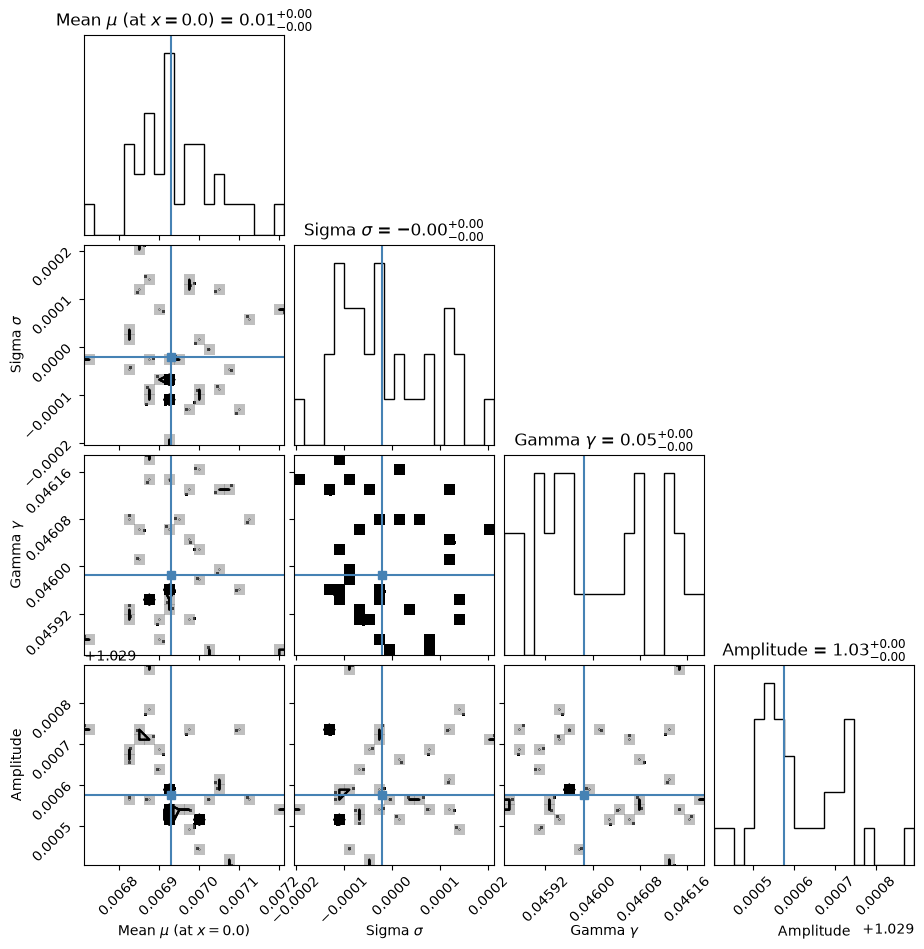

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m>9_z=10.0.h5
Median sigma: -0.000, mean: 0.007, amplitude: 1.030
m bin:  [9.0, 11]
z bin:  [10.5, 11.5]
Number of gals in bin:  14
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m>9_z=11.0.h5
FWHM initial guess:  0.14205772636120984
Guesses: mean = 0.015, sig = 0.000, gamma = 0.091, amp = 1.052


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2183.49it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = 40.569


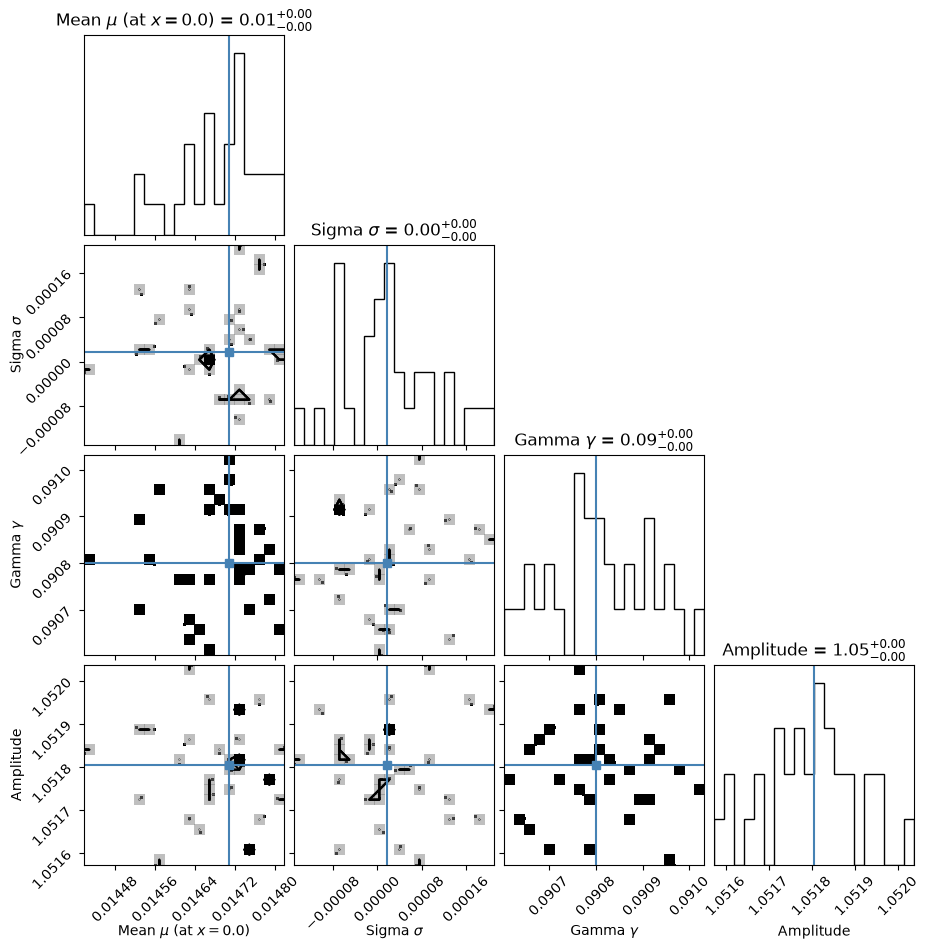

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m>9_z=11.0.h5
Median sigma: 0.000, mean: 0.015, amplitude: 1.052
m bin:  [9.0, 11]
z bin:  [11.5, 13.5]
Number of gals in bin:  15
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m>9_z=12.5.h5
FWHM initial guess:  0.32616727903479836
Guesses: mean = 0.038, sig = 0.032, gamma = 0.185, amp = 0.958


100%|██████████| 5000/5000 [00:07<00:00, 676.97it/s]


Reduced chi squared = 15.611


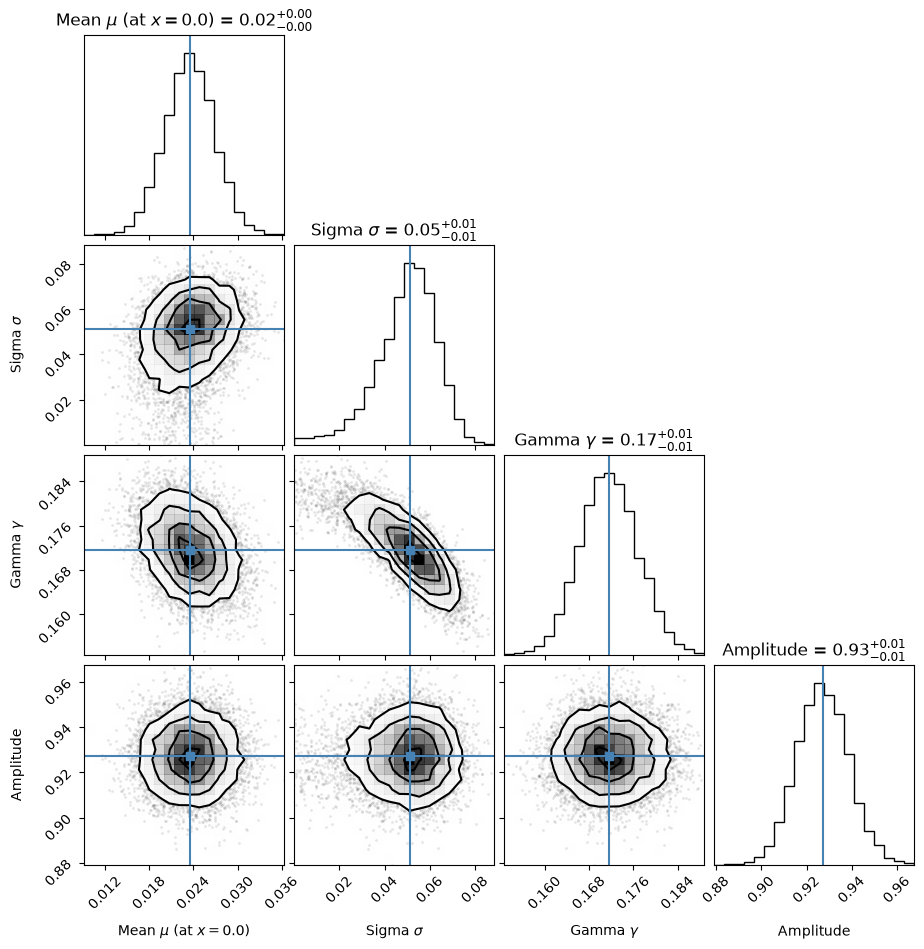

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m>9_z=12.5.h5
Median sigma: 0.051, mean: 0.024, amplitude: 0.927
m bin:  [8, 9.0]
z bin:  [6.5, 7.5]
Number of gals in bin:  314
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m=8-9_z=7.0.h5
FWHM initial guess:  0.3994807813099097
Guesses: mean = -0.017, sig = 0.213, gamma = 0.037, amp = 0.991


100%|██████████| 5000/5000 [00:07<00:00, 647.58it/s]


Reduced chi squared = 24.212


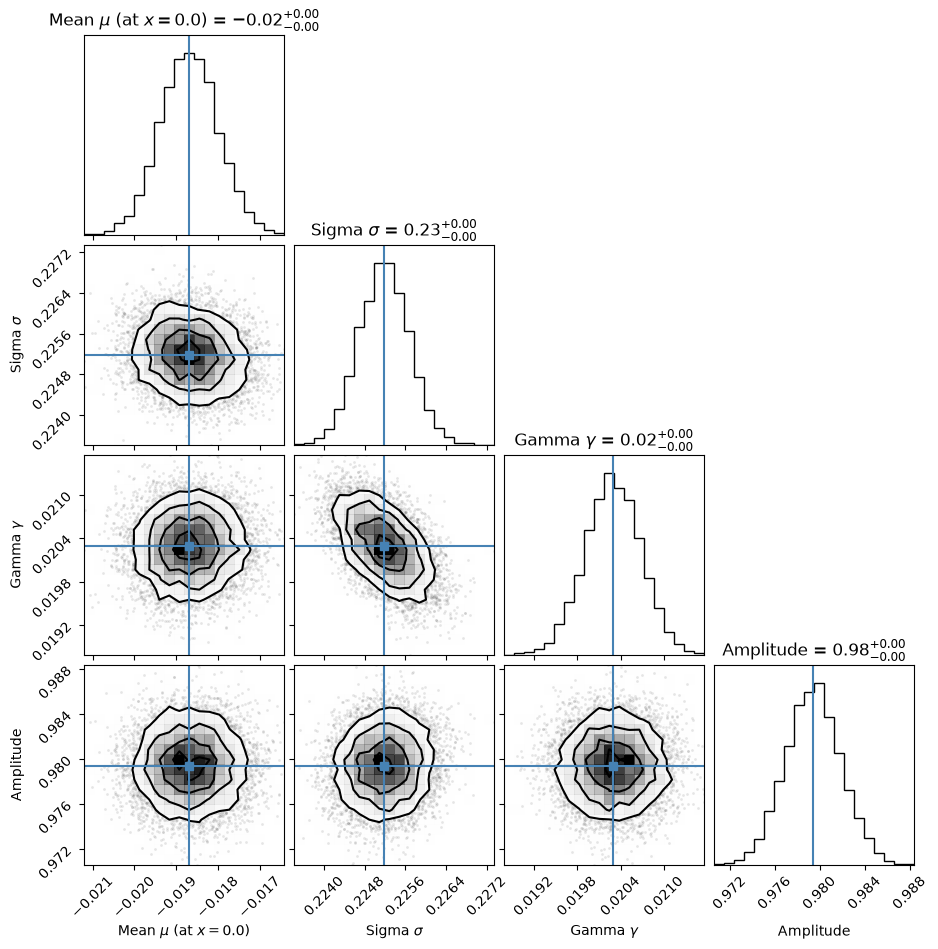

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m=8-9_z=7.0.h5
Median sigma: 0.225, mean: -0.019, amplitude: 0.979
m bin:  [8, 9.0]
z bin:  [7.5, 8.5]
Number of gals in bin:  137
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m=8-9_z=8.0.h5
FWHM initial guess:  0.2190533992810171
Guesses: mean = 0.001, sig = 0.017, gamma = 0.120, amp = 1.082


100%|██████████| 5000/5000 [00:07<00:00, 673.40it/s]


Reduced chi squared = 116.433


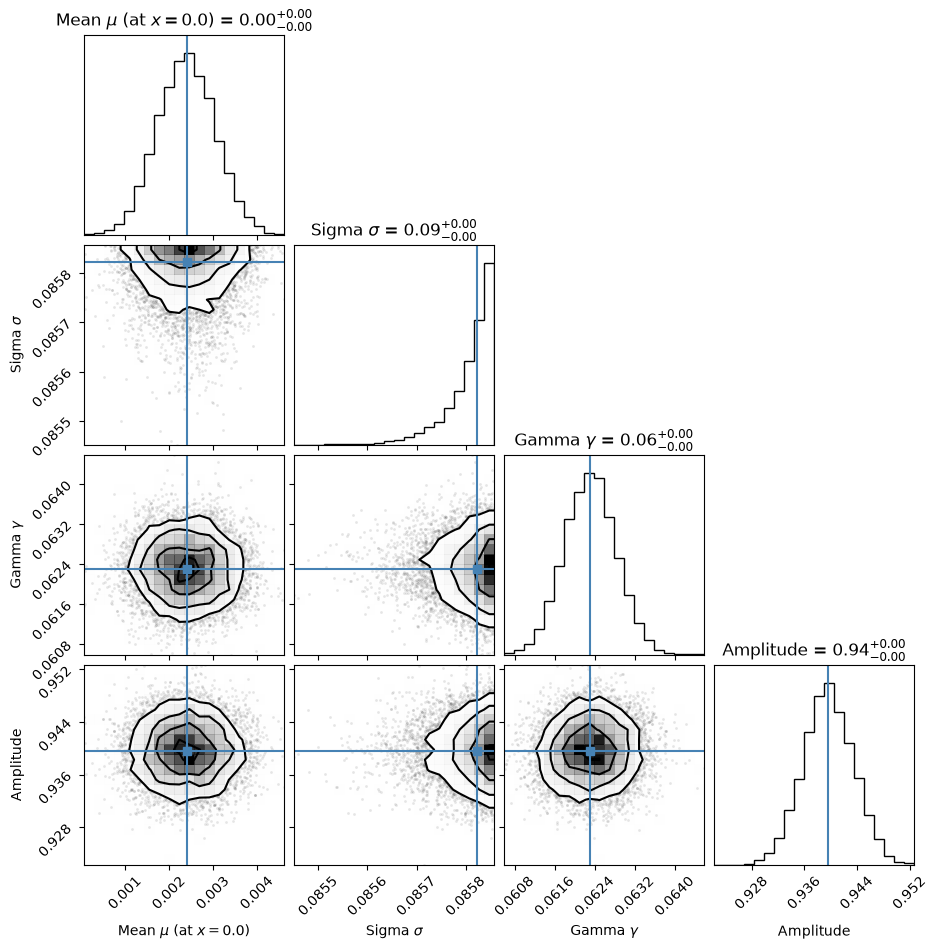

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m=8-9_z=8.0.h5
Median sigma: 0.086, mean: 0.002, amplitude: 0.940
m bin:  [8, 9.0]
z bin:  [8.5, 9.5]
Number of gals in bin:  47
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m=8-9_z=9.0.h5
FWHM initial guess:  0.24552585720671066
Guesses: mean = 0.003, sig = 0.026, gamma = 0.140, amp = 1.069


100%|██████████| 5000/5000 [00:07<00:00, 651.70it/s]


Reduced chi squared = 40.275


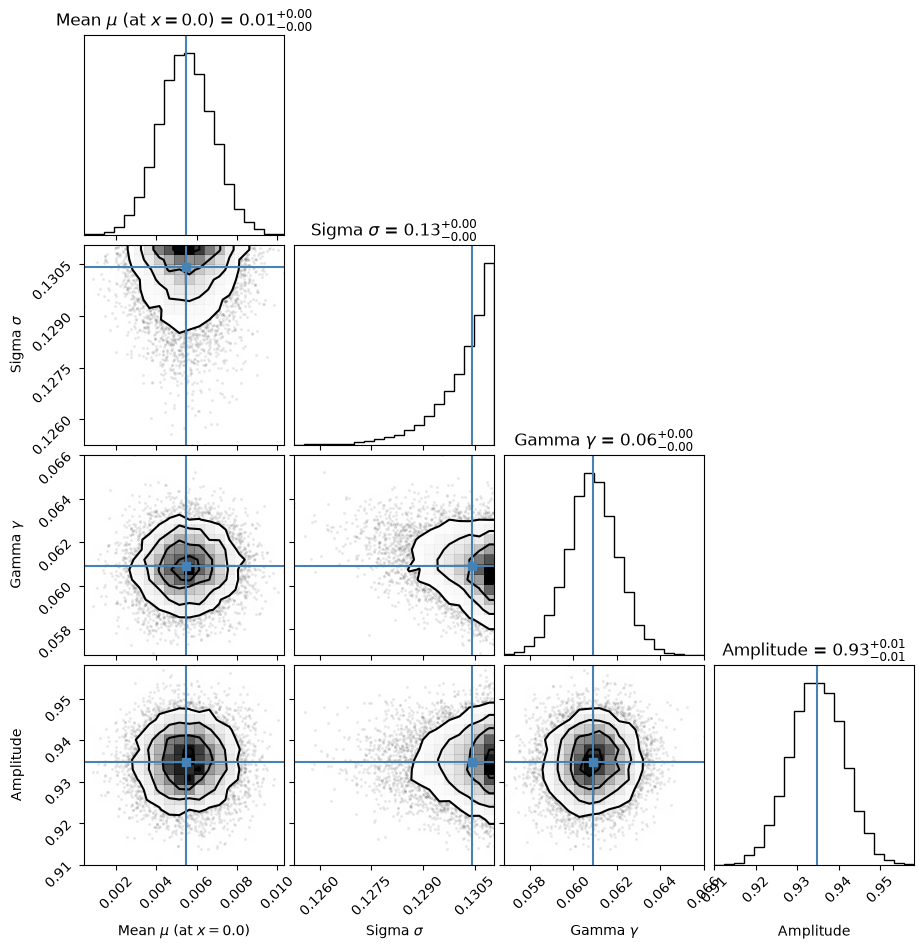

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m=8-9_z=9.0.h5
Median sigma: 0.130, mean: 0.005, amplitude: 0.935
m bin:  [8, 9.0]
z bin:  [9.5, 10.5]
Number of gals in bin:  47
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m=8-9_z=10.0.h5
FWHM initial guess:  0.31735250213615485
Guesses: mean = 0.019, sig = 0.000, gamma = 0.179, amp = 1.077


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1843.73it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = inf


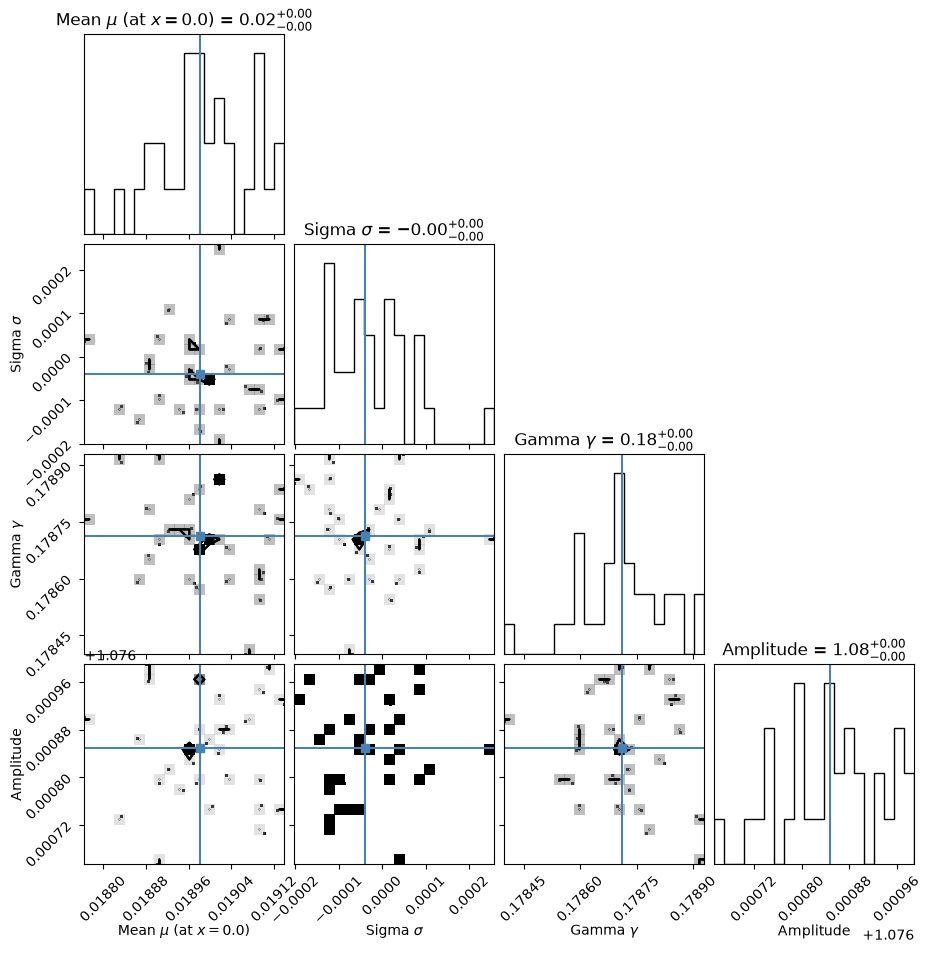

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m=8-9_z=10.0.h5
Median sigma: -0.000, mean: 0.019, amplitude: 1.077
m bin:  [8, 9.0]
z bin:  [10.5, 11.5]
Number of gals in bin:  45
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m=8-9_z=11.0.h5
FWHM initial guess:  0.3115849395230834
Guesses: mean = 0.041, sig = 0.000, gamma = 0.215, amp = 1.005


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:03<00:00, 1518.51it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = inf


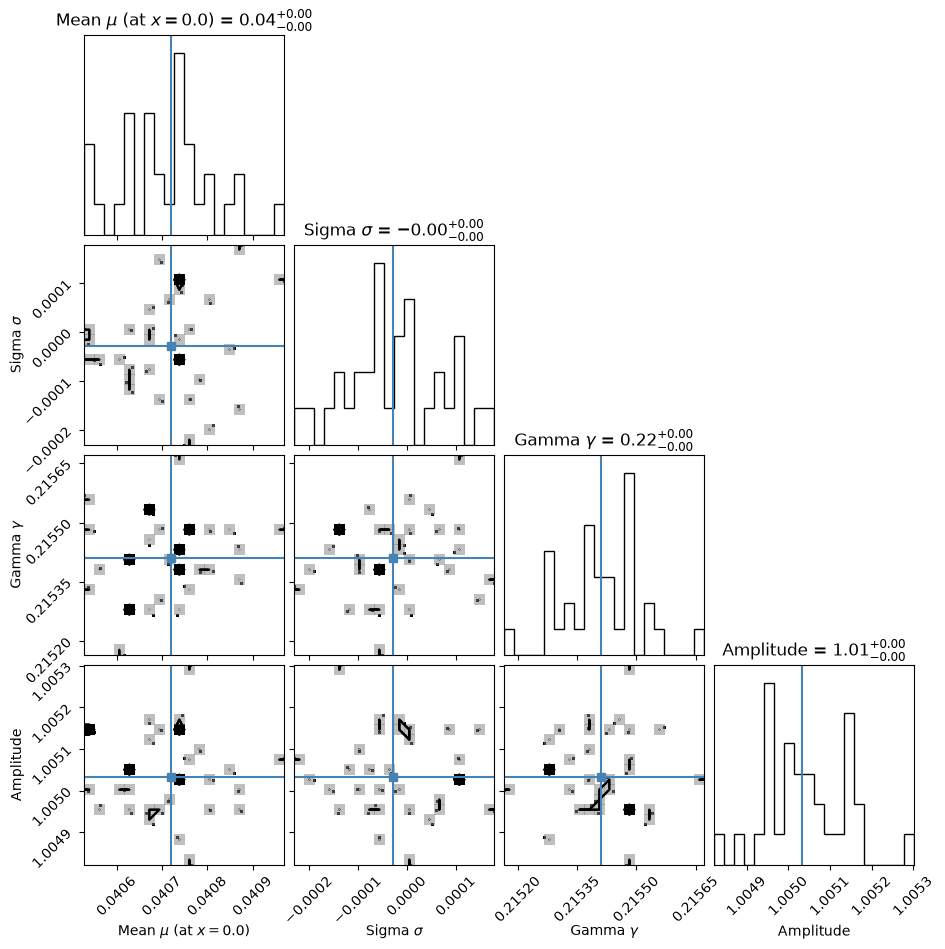

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m=8-9_z=11.0.h5
Median sigma: -0.000, mean: 0.041, amplitude: 1.005
m bin:  [8, 9.0]
z bin:  [11.5, 13.5]
Number of gals in bin:  42
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m=8-9_z=12.5.h5
FWHM initial guess:  0.2566138464407586
Guesses: mean = 0.032, sig = 0.000, gamma = 0.179, amp = 0.909


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1888.90it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = inf


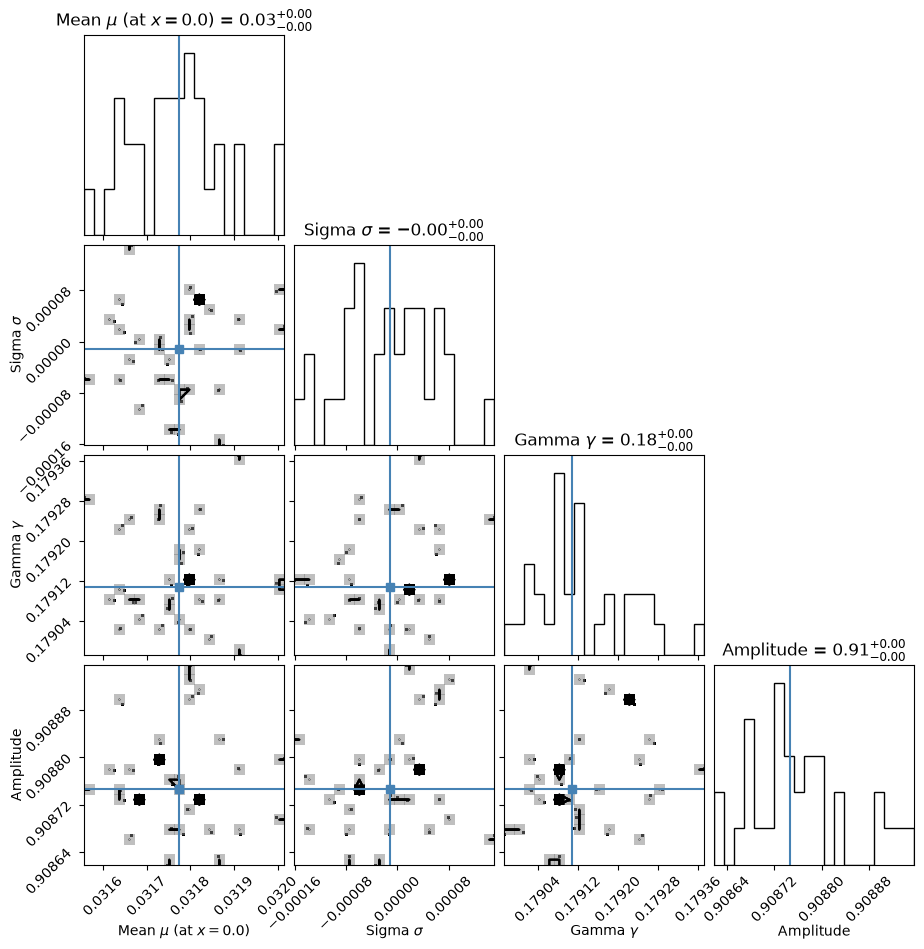

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m=8-9_z=12.5.h5
Median sigma: -0.000, mean: 0.032, amplitude: 0.909
m bin:  [5, 8]
z bin:  [6.5, 7.5]
Number of gals in bin:  958
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m<8_z=7.0.h5
FWHM initial guess:  0.2231010115645764
Guesses: mean = -0.014, sig = 0.000, gamma = 0.123, amp = 1.118


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1684.56it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = 60243.791


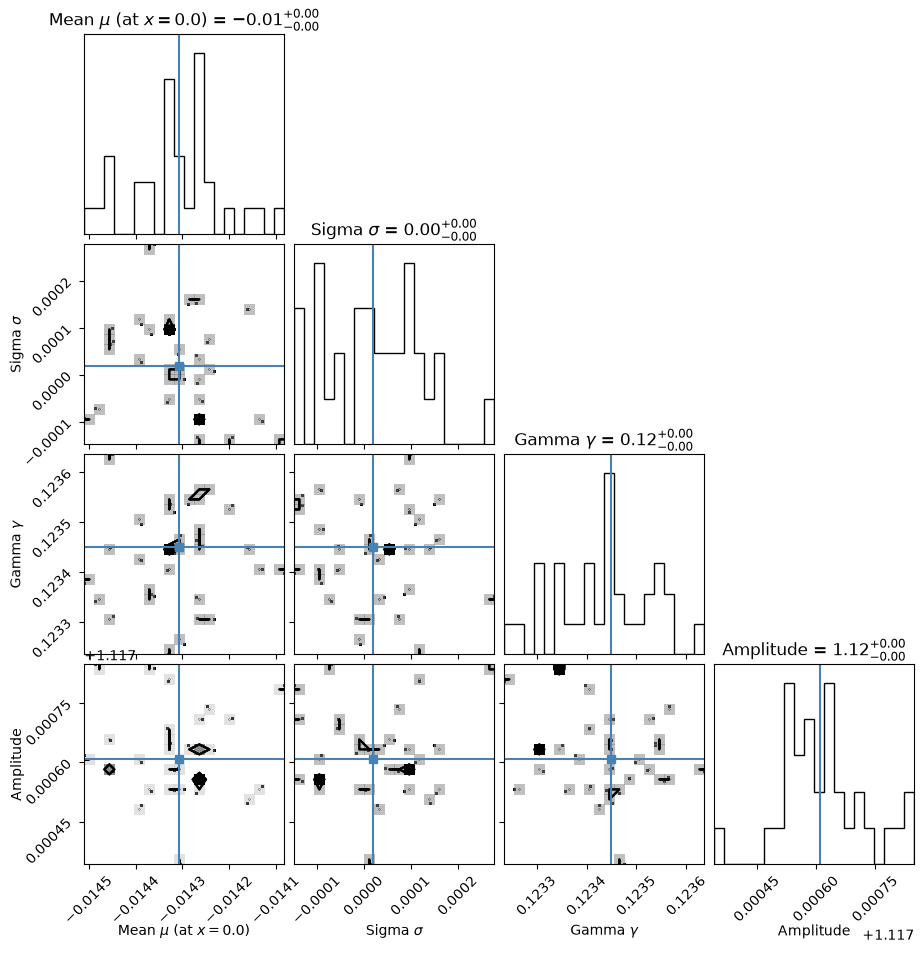

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m<8_z=7.0.h5
Median sigma: 0.000, mean: -0.014, amplitude: 1.118
m bin:  [5, 8]
z bin:  [7.5, 8.5]
Number of gals in bin:  406
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m<8_z=8.0.h5
FWHM initial guess:  0.20834587617618422
Guesses: mean = -0.015, sig = 0.000, gamma = 0.129, amp = 1.085


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:03<00:00, 1594.82it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = 9289.480


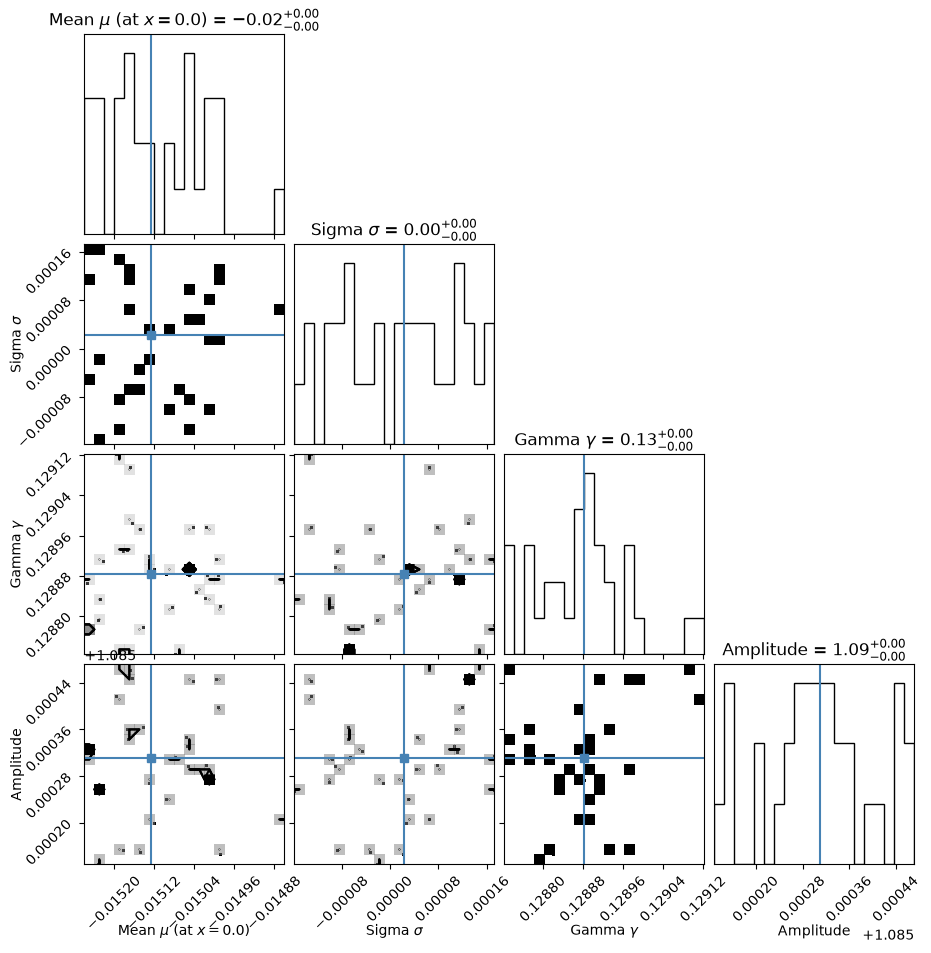

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m<8_z=8.0.h5
Median sigma: 0.000, mean: -0.015, amplitude: 1.085
m bin:  [5, 8]
z bin:  [8.5, 9.5]
Number of gals in bin:  173
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m<8_z=9.0.h5
FWHM initial guess:  0.2238528255536571
Guesses: mean = -0.020, sig = 0.000, gamma = 0.131, amp = 1.051


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1973.01it/s]
/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


Reduced chi squared = inf


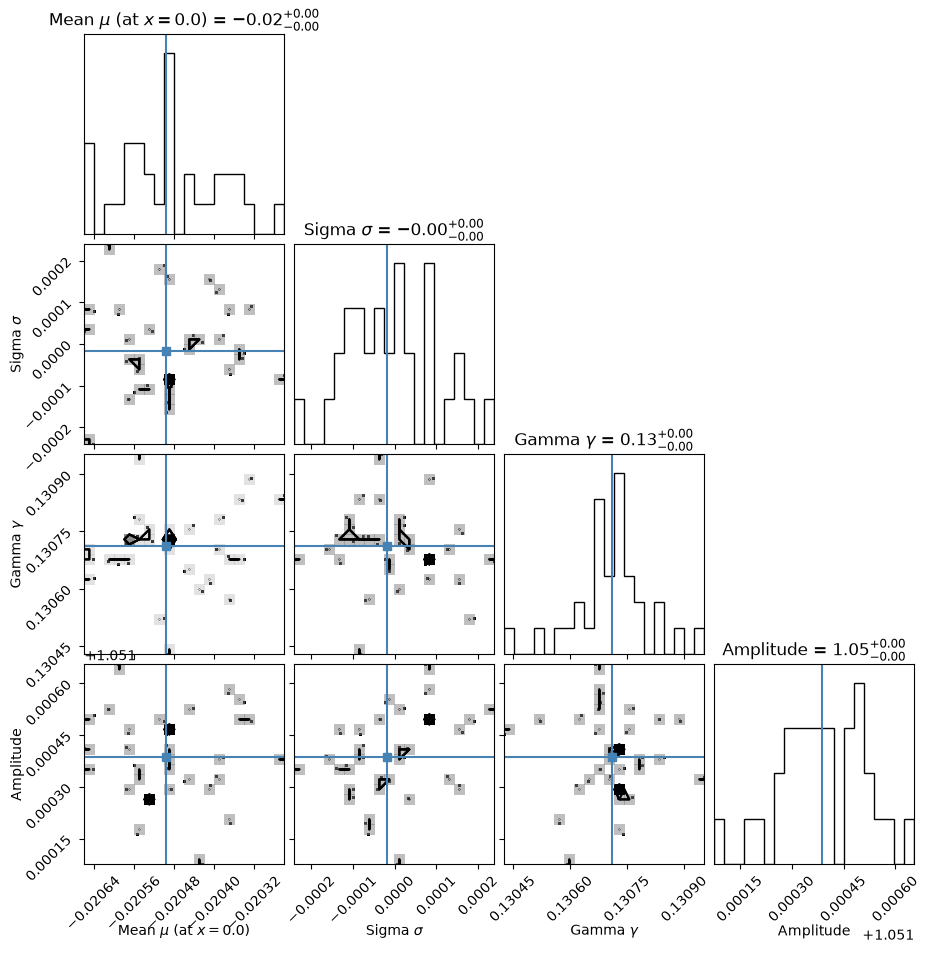

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m<8_z=9.0.h5
Median sigma: -0.000, mean: -0.020, amplitude: 1.051
m bin:  [5, 8]
z bin:  [9.5, 10.5]
Number of gals in bin:  68
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m<8_z=10.0.h5
FWHM initial guess:  0.5631651537423753
Guesses: mean = -0.019, sig = 0.109, gamma = 0.243, amp = 1.127


100%|██████████| 5000/5000 [00:07<00:00, 626.44it/s]


Reduced chi squared = 37.069


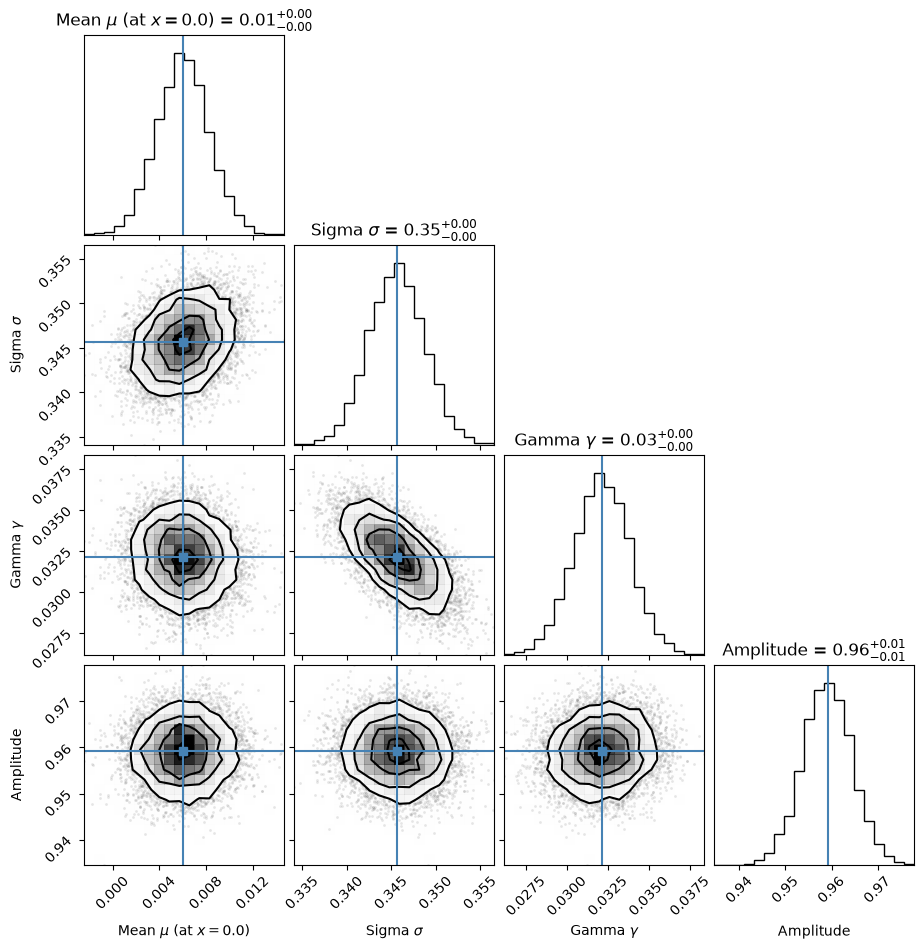

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m<8_z=10.0.h5
Median sigma: 0.346, mean: 0.006, amplitude: 0.959
m bin:  [5, 8]
z bin:  [10.5, 11.5]
Number of gals in bin:  40
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m<8_z=11.0.h5
FWHM initial guess:  0.6337873359862224
Guesses: mean = -0.035, sig = 0.110, gamma = 0.337, amp = 1.179


100%|██████████| 5000/5000 [00:07<00:00, 636.00it/s]


Reduced chi squared = 20.818


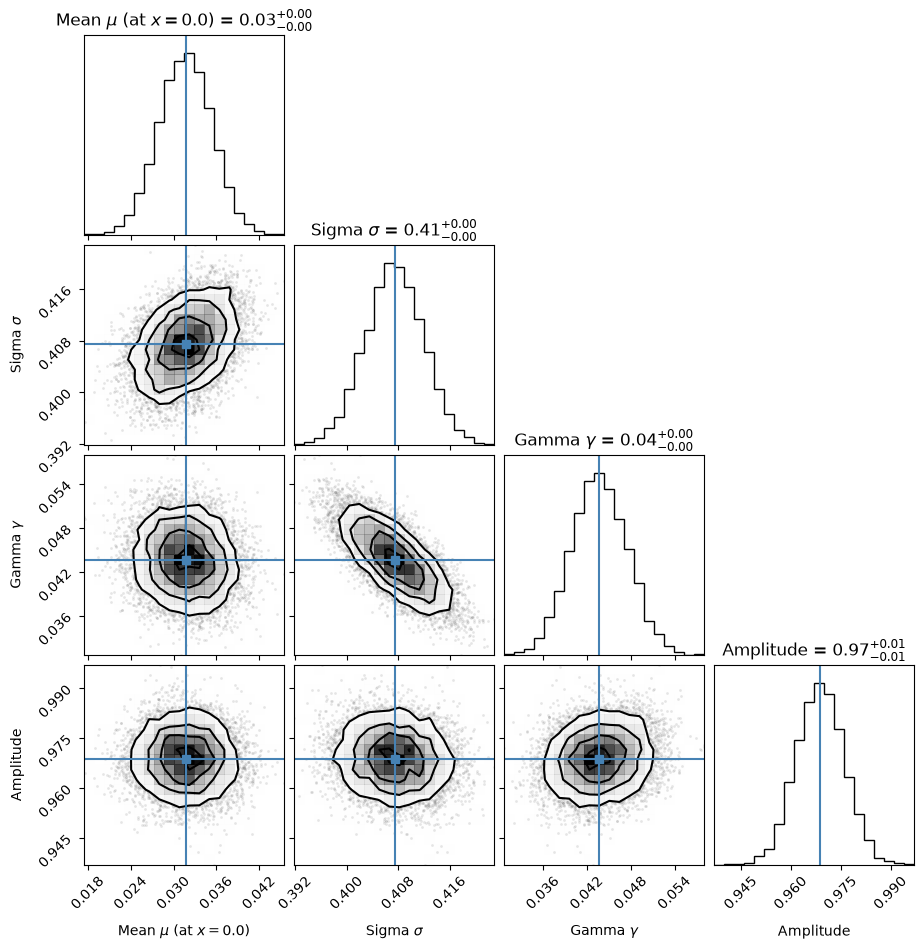

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m<8_z=11.0.h5
Median sigma: 0.407, mean: 0.032, amplitude: 0.969
m bin:  [5, 8]
z bin:  [11.5, 13.5]
Number of gals in bin:  20
FWHM path:  /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/FWHM_results/results_table_m<8_z=12.5.h5
FWHM initial guess:  1.2455123674199033
Guesses: mean = -0.013, sig = 0.561, gamma = 0.000, amp = 1.046


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1738.93it/s]


Reduced chi squared = 38.713


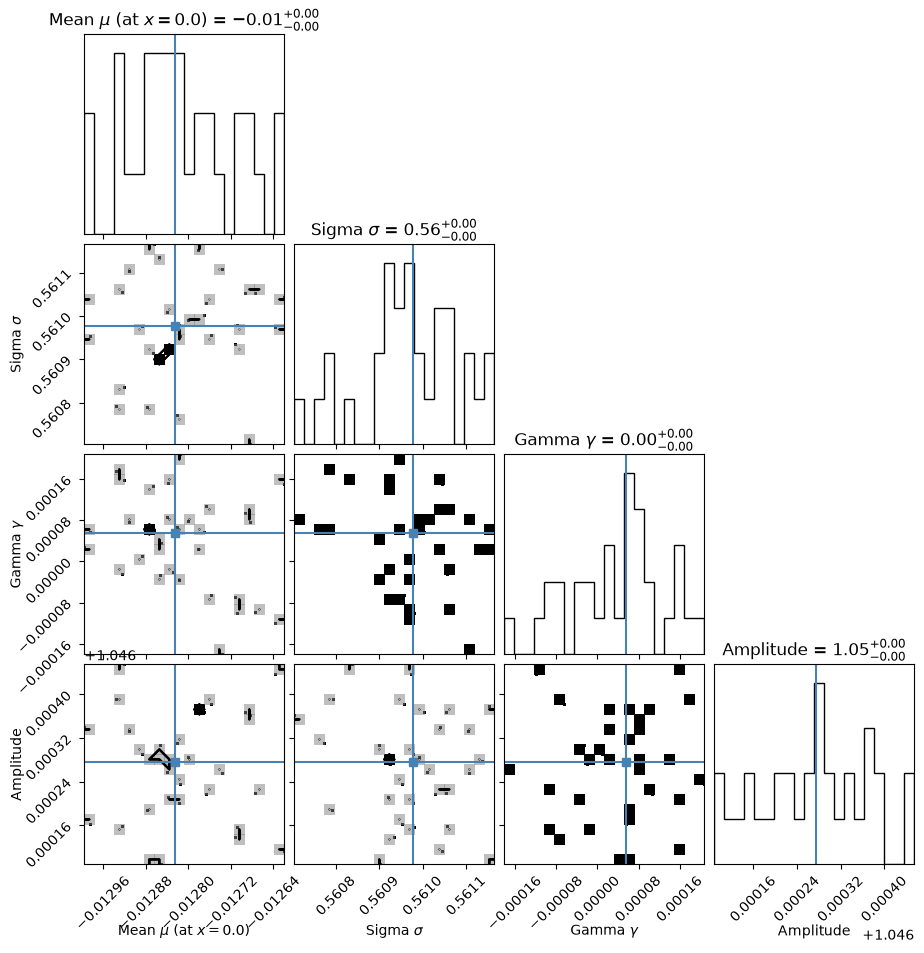

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Voigt_fit_results/results_table_m<8_z=12.5.h5
Median sigma: 0.561, mean: -0.013, amplitude: 1.046


In [286]:
if __name__ == "__main__":

    with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

        sample_table = hdu[1].data
    sample_table = Table(sample_table)

    SFH_models = ["Bagpipes_sfh_cont_bursty_zEAZYsfhzblueagn_3.0,10.0Myr_Calzetti_log_10_Z_log_10_BPASS_zfix"]

    get_posterior(sample_table, SFH_models[0], refit=True)            